Check for gpu

In [ ]:
# Get GPU name
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-572dde43-4a7f-eeca-c2b7-65ea13b38104)


In [ ]:
model_name = "yolo11s-seg"

# DATASET
**From Roboflow**
- https://universe.roboflow.com/seg2/dental_project-ee1ur
- https://universe.roboflow.com/dental-z05ko/gum-diseases

**Merged and curated**
- https://universe.roboflow.com/pranta/oralcure_dataset/dataset/2

In [ ]:
!pip install --upgrade ultralytics onnxruntime onnxruntime-gpu onnxslim roboflow supervision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.8/280.8 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.3/85.3 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 181.5/181.5 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883

**Dataset overview**

*V1*
- image count - 582
  - Train - 429
  - Valid - 77
  - Test  - rest
- Annotaion count per class
  - Train (Caries/Gingivitis/MouthUlcer/Periodontitis) - 300
  - Valid (Caries/Gingivitis/MouthUlcer/Periodontitis) - 46
  - Test  (Caries/Gingivitis/MouthUlcer/Periodontitis) - REST

*V2*
- applied augmentation on V1 train image (430x3) annotation (300x3)
  - Outputs per training example: 3
  - Flip: Horizontal
  - Rotation: Between -5° and +5°
  - Shear: ±3° Horizontal, ±3° Vertical
  - Brightness: Between -10% and +10%
  - Exposure: Between -5% and +5%
  - Blur: Up to 1.5px
  - Noise: Up to 1% of pixels

*V3*
- applied augmentation on V2 train image (1287x3) annotation (900x3)
  - Apply very mild transformations to the V2 train set (1290 images):
  - Rotation: ±2° (minimal adjustment).
  - Brightness: ±5% (subtle change).
  - Noise: Up to 0.5% of pixels (very light).

## Downloading Data

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

!mkdir {HOME}/datasets
%cd {HOME}/datasets

from roboflow import Roboflow
from google.colab import userdata

roboflow_api_key = userdata.get('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("pranta").project("oralcure_dataset")
version = project.version(2)
dataset = version.download("yolov11")

/content
/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dental_disease_seg_baln_reaug-2 in yolov11:: 100%|██████████| 1176/1176 [00:00<00:00, 7908.11it/s]


# Feature Extractor model

## Training Object Detection model

In [ ]:
from ultralytics import YOLO

# Load a model
feature_extractor_model = YOLO(f"{model_name}.pt")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 19.7M/19.7M [00:00<00:00, 144MB/s] 


In [ ]:
feature_extractor_model.info()

YOLO11s-seg summary: 203 layers, 10,113,248 parameters, 0 gradients, 35.8 GFLOPs


(203, 10113248, 0, 35.7621248)

YOLO11s-seg model has the following specifications:
* Layer Count: 355 layers
* Parameter Count: 10,113,248 parameters
* Gradient Count: 0 gradients (indicating that no parameters are set to require * gradients, which is typical for a feature extraction setup)
* GFLOPs: 35.8 GFLOPs (Giga Floating Point Operations per Second)

In [ ]:
feature_extractor_model.model.yaml

{'nc': 80,
 'scales': {'n': [0.5, 0.25, 1024],
  's': [0.5, 0.5, 1024],
  'm': [0.5, 1.0, 512],
  'l': [1.0, 1.0, 512],
  'x': [1.0, 1.5, 512]},
 'backbone': [[-1, 1, 'Conv', [64, 3, 2]],
  [-1, 1, 'Conv', [128, 3, 2]],
  [-1, 2, 'C3k2', [256, False, 0.25]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [-1, 2, 'C3k2', [512, False, 0.25]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [-1, 2, 'C3k2', [512, True]],
  [-1, 1, 'Conv', [1024, 3, 2]],
  [-1, 2, 'C3k2', [1024, True]],
  [-1, 1, 'SPPF', [1024, 5]],
  [-1, 2, 'C2PSA', [1024]]],
 'head': [[-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 6], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 4], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [256, False]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [[-1, 13], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [[-1, 10], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [1024, True]],
  [[16, 19, 22], 1, 'Segment', ['nc', 32, 256]]],
 

In [ ]:
for i, layer in enumerate(feature_extractor_model.model.model):
    print(i, layer)

0 Conv(
  (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
  (act): SiLU(inplace=True)
)
1 Conv(
  (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
  (act): SiLU(inplace=True)
)
2 C3k2(
  (cv1): Conv(
    (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv2): Conv(
    (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (m): ModuleList(
    (0): Bottleneck(
      (cv1): Conv(
        (conv): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=

In [ ]:
for i, param in enumerate(feature_extractor_model.model.parameters()):
    print(f"Layer {i}: {'Frozen' if not param.requires_grad else 'Trainable'}")

Layer 0: Frozen
Layer 1: Frozen
Layer 2: Frozen
Layer 3: Frozen
Layer 4: Frozen
Layer 5: Frozen
Layer 6: Frozen
Layer 7: Frozen
Layer 8: Frozen
Layer 9: Frozen
Layer 10: Frozen
Layer 11: Frozen
Layer 12: Frozen
Layer 13: Frozen
Layer 14: Frozen
Layer 15: Frozen
Layer 16: Frozen
Layer 17: Frozen
Layer 18: Frozen
Layer 19: Frozen
Layer 20: Frozen
Layer 21: Frozen
Layer 22: Frozen
Layer 23: Frozen
Layer 24: Frozen
Layer 25: Frozen
Layer 26: Frozen
Layer 27: Frozen
Layer 28: Frozen
Layer 29: Frozen
Layer 30: Frozen
Layer 31: Frozen
Layer 32: Frozen
Layer 33: Frozen
Layer 34: Frozen
Layer 35: Frozen
Layer 36: Frozen
Layer 37: Frozen
Layer 38: Frozen
Layer 39: Frozen
Layer 40: Frozen
Layer 41: Frozen
Layer 42: Frozen
Layer 43: Frozen
Layer 44: Frozen
Layer 45: Frozen
Layer 46: Frozen
Layer 47: Frozen
Layer 48: Frozen
Layer 49: Frozen
Layer 50: Frozen
Layer 51: Frozen
Layer 52: Frozen
Layer 53: Frozen
Layer 54: Frozen
Layer 55: Frozen
Layer 56: Frozen
Layer 57: Frozen
Layer 58: Frozen
Layer 5

Training setting for yolo -> https://docs.ultralytics.com/modes/train/#train-settings

In [ ]:
feature_extraction_results = feature_extractor_model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=32,
    freeze=11,
    lr0=0.01,
    cos_lr=True,
    patience=20,
    amp=True,
    save=True,
    device=0,
    seed=42
)

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=yolo11s-seg.pt, data=/content/datasets/dental_disease_seg_baln_reaug-2/data.yaml, epochs=50, time=None, patience=20, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=11, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=Tr

100%|██████████| 755k/755k [00:00<00:00, 19.1MB/s]


Overriding model.yaml nc=80 with nc=4

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  3                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  4                  -1  1    103360  ultralytics.nn.modules.block.C3k2            [128, 256, 1, False, 0.25]    
  5                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  6                  -1  1    346112  ultralytics.nn.modules.block.C3k2            [256, 256, 1, True]           
  7                  -1  1   1180672  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 93.1MB/s]


AMP: checks passed ✅


train: Scanning /content/datasets/dental_disease_seg_baln_reaug-2/train/labels... 429 images, 0 backgrounds, 0 corrupt: 100%|██████████| 429/429 [00:00<00:00, 1708.52it/s]

... (147 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  50%|█████     | 1/2 [00:01<00:01,  1.02s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:01<00:00,  1.28it/s]


                   all         77        184      0.479      0.587      0.487      0.261      0.474      0.581      0.481      0.221
                Caries         22         46      0.624      0.543      0.567      0.216      0.646      0.565       0.59      0.212
            Gingivitis         12         46      0.392      0.435      0.395      0.209      0.365      0.412      0.355      0.136
           Mouth Ulcer         29         46      0.642      0.543      0.554      0.396      0.637      0.543      0.552      0.377
         Periodontitis         19         46      0.258      0.826      0.433      0.225       0.25      0.804      0.425       0.16
Speed: 0.2ms preprocess, 7.1ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to runs/segment/train


## Save model performance and best weights in drive

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/feature_extractor"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/feature_extractor.


## Plot model results

In [ ]:
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
from IPython.display import Image

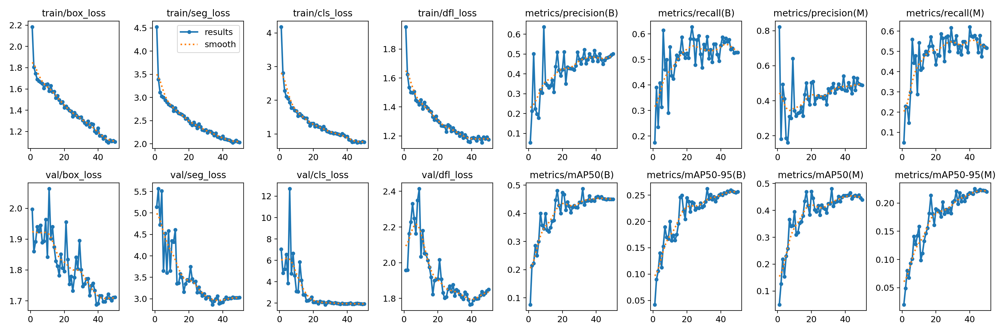

In [ ]:
results_path = f"{saved_model_results_path}/train/results.png"
Image(results_path, width=1000)

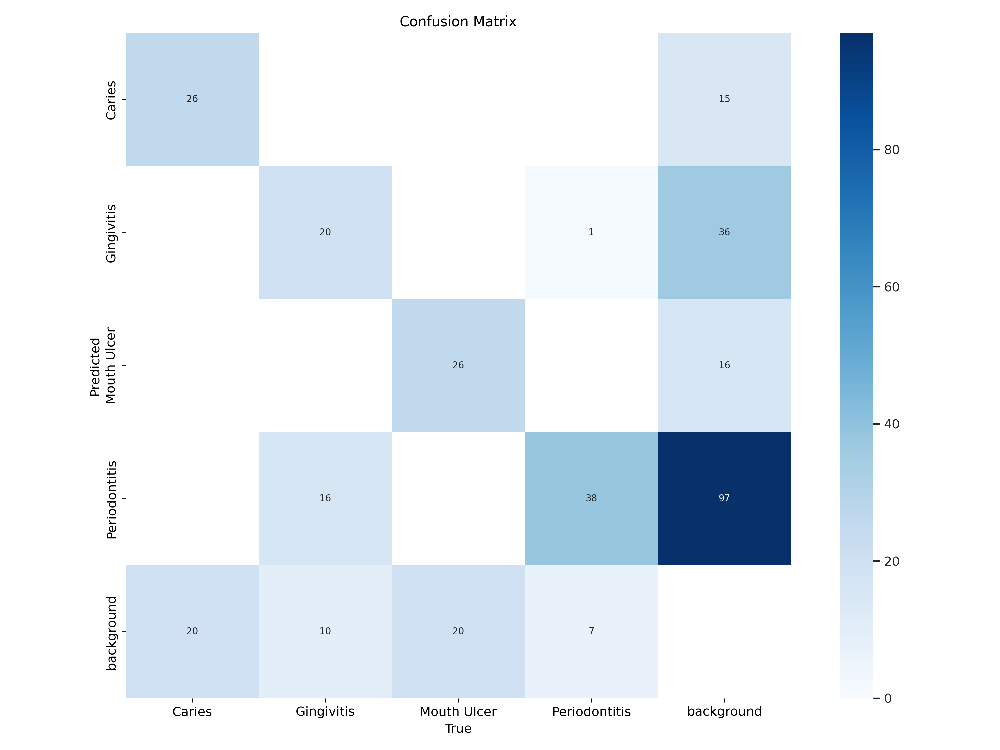

In [ ]:
confusion_matrix_path = f"{saved_model_results_path}/train/confusion_matrix.png"
Image(confusion_matrix_path, width=800)

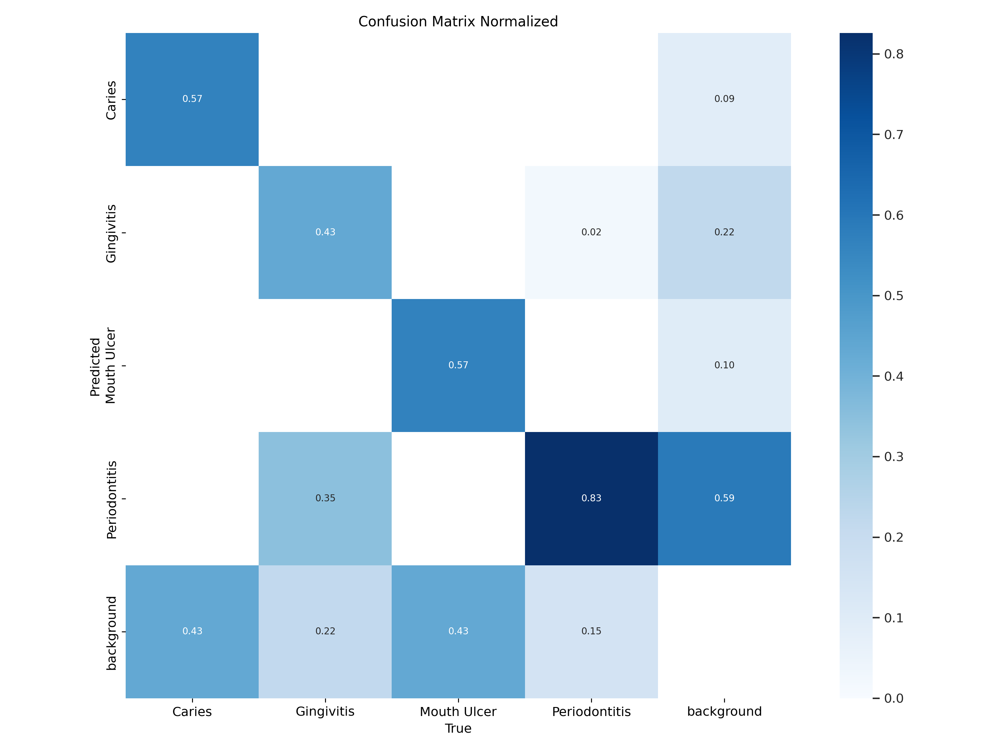

In [ ]:
confusion_matrix_norm_path = f"{saved_model_results_path}/train/confusion_matrix_normalized.png"
Image(confusion_matrix_norm_path, width=800)

### Segmentation results

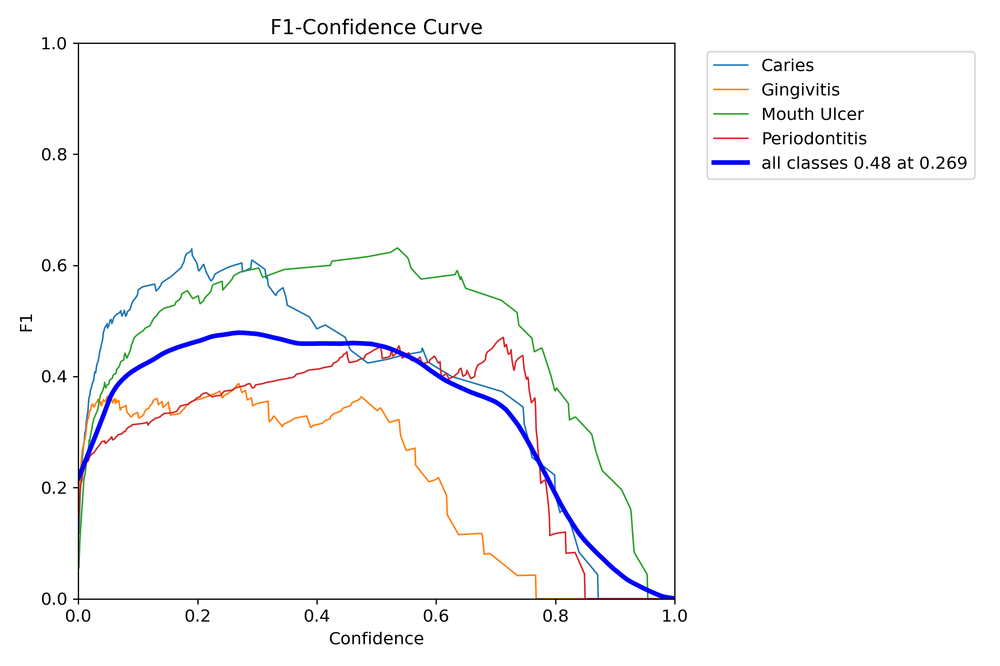

In [ ]:
# mask or segmentation f1 score
f1_curve_path = f"{saved_model_results_path}/train/MaskF1_curve.png"
Image(f1_curve_path, width=800)

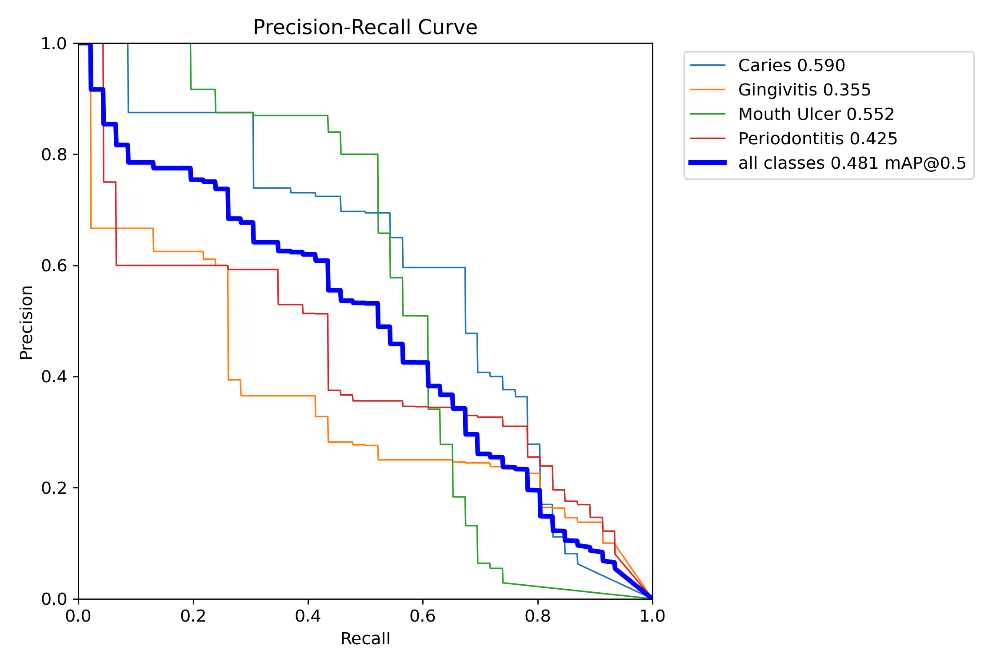

In [ ]:
pr_curve = f"{saved_model_results_path}/train/MaskPR_curve.png"
Image(pr_curve, width=800)

### Detection results

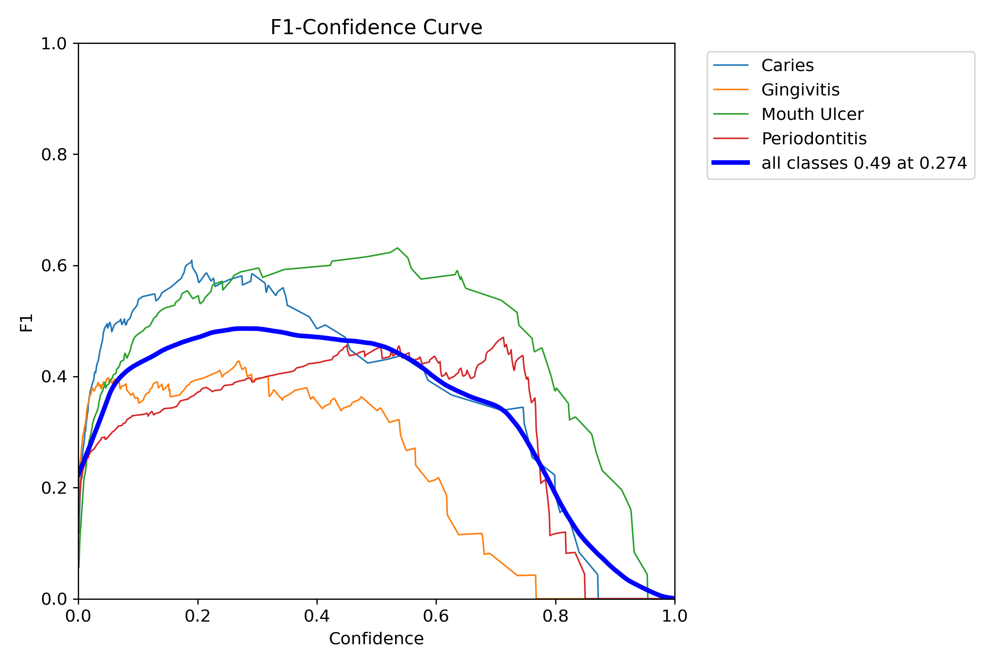

In [ ]:
# bounding box or detection f1 score
f1_curve_box_path = f"{saved_model_results_path}/train/BoxF1_curve.png"
Image(f1_curve_box_path, width=800)

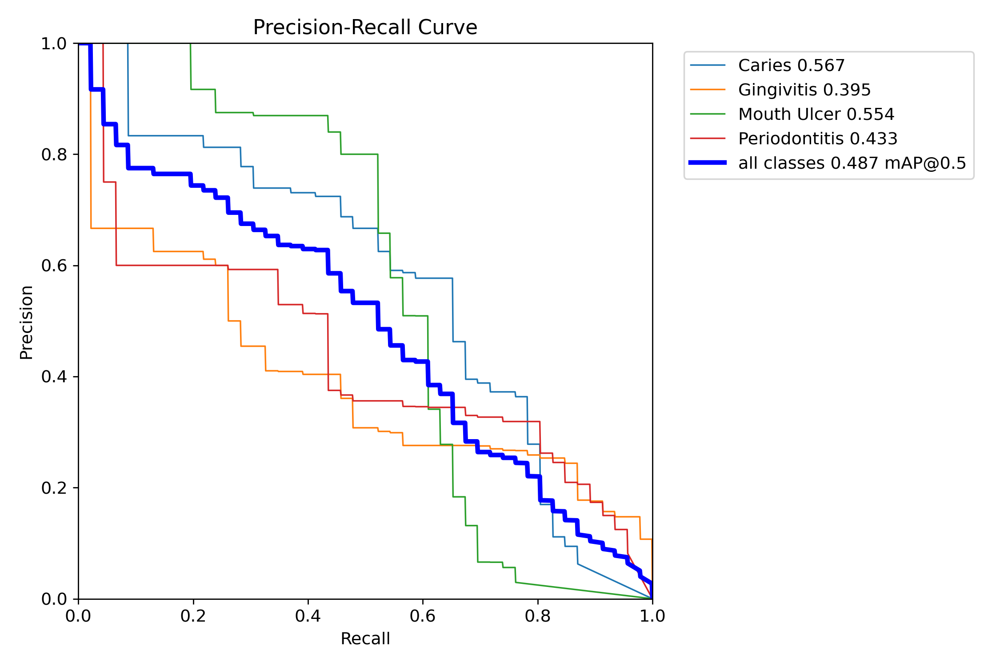

In [ ]:
pr_curve_box_path = f"{saved_model_results_path}/train/BoxPR_curve.png"
Image(pr_curve_box_path, width=800)

### Labels

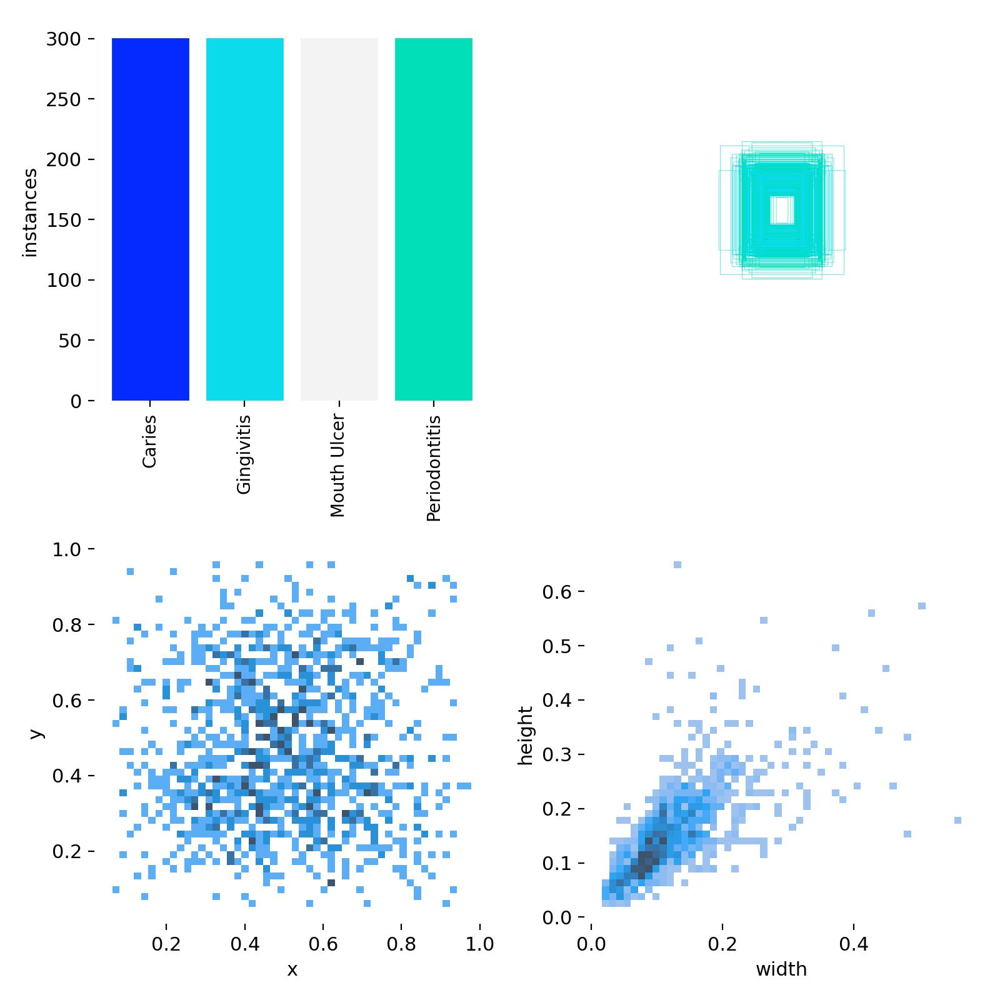

In [ ]:
labels_path = f"{saved_model_results_path}/train/labels.jpg"
Image(labels_path, width=800)

# Validation

In [ ]:
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
fe_loaded_best_model = YOLO(best_weights_path)

In [ ]:
fe_loaded_best_model.val()

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s-seg summary (fused): 113 layers, 10,068,364 parameters, 0 gradients, 35.3 GFLOPs


val: Scanning /content/datasets/dental_disease_seg_baln_reaug-2/valid/labels.cache... 77 images, 0 backgrounds, 0 corrupt: 100%|██████████| 77/77 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):   0%|          | 0/5 [00:00<?, ?it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  20%|██        | 1/5 [00:00<00:03,  1.26it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  40%|████      | 2/5 [00:01<00:02,  1.18it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:06<00:00,  1.33s/it]


                   all         77        184      0.478      0.591      0.487      0.262      0.474      0.579       0.48       0.22
                Caries         22         46      0.623      0.543      0.565      0.216      0.649      0.565      0.587      0.212
            Gingivitis         12         46        0.4       0.45      0.395      0.209      0.359      0.402      0.356      0.136
           Mouth Ulcer         29         46      0.634      0.543      0.551      0.394      0.636      0.543       0.55      0.373
         Periodontitis         19         46      0.257      0.826      0.437      0.228      0.251      0.804      0.429      0.161
Speed: 15.8ms preprocess, 21.2ms inference, 0.0ms loss, 6.6ms postprocess per image
Results saved to runs/segment/val


ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e76e3270050>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0

## Save validation results

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs/segment/val"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/feature_extractor/segment/val"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs/segment/val have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/feature_extractor/segment/val.


## Plot a validation image


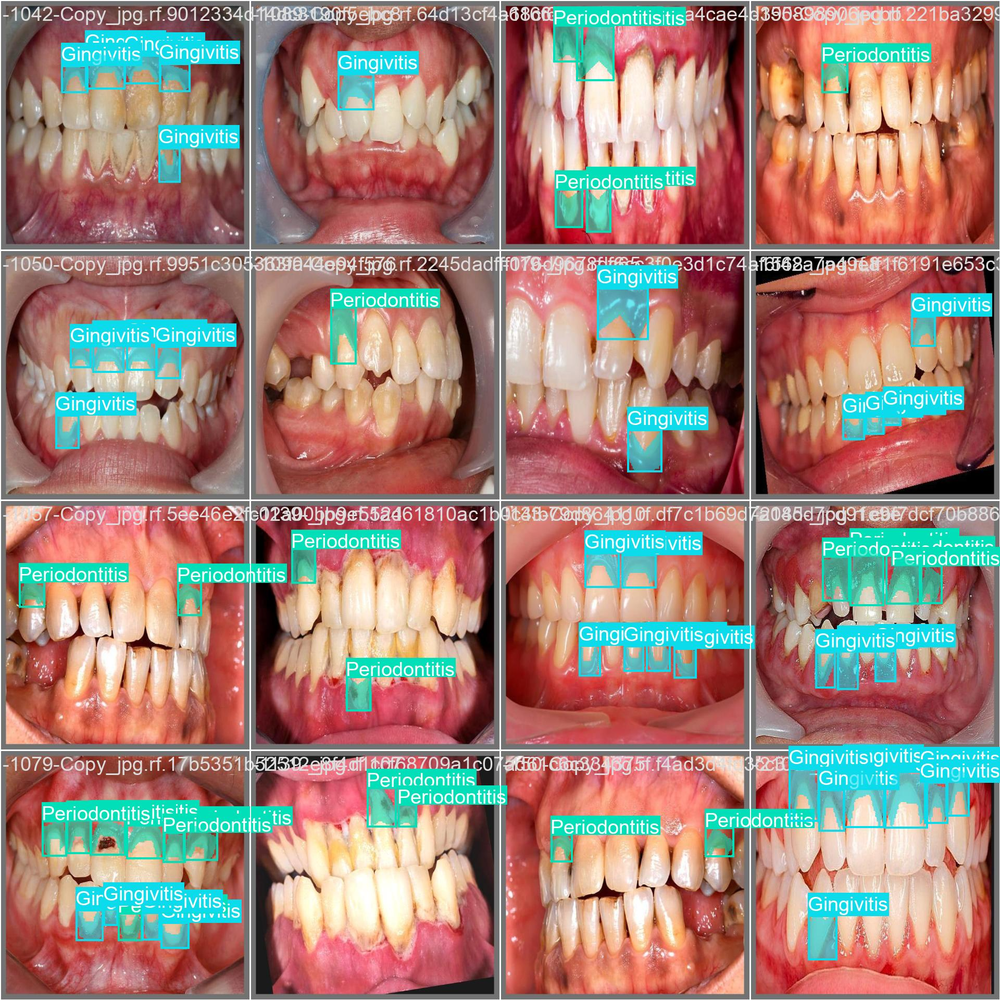

In [ ]:
validation_batch_labels = f"{saved_model_results_path}/val/val_batch0_labels.jpg"
Image(validation_batch_labels, width=1000)

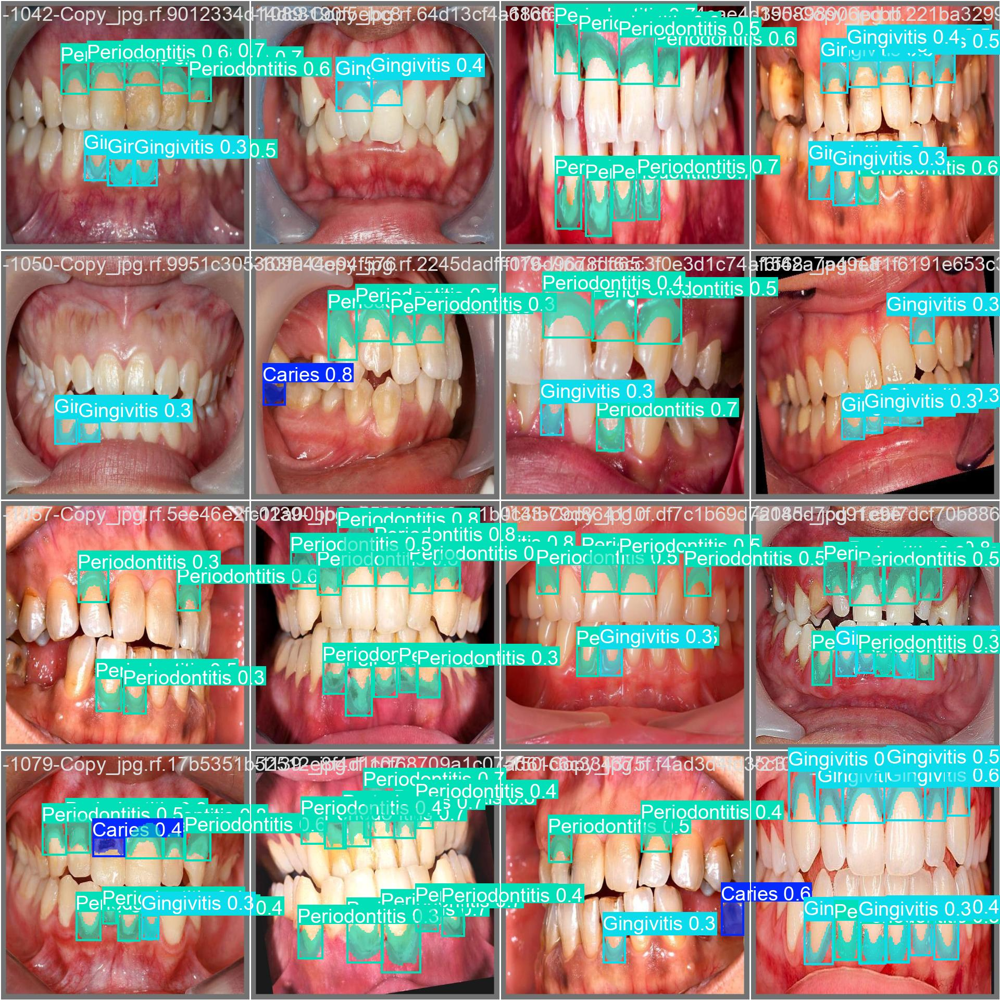

In [ ]:
validation_batch_pred = f"{saved_model_results_path}/val/val_batch0_pred.jpg"
Image(validation_batch_pred, width=1000)

# Model Fine Tuning (IN PROGRESS)

## Dowload augmented data

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

!mkdir {HOME}/datasets
%cd {HOME}/datasets

from roboflow import Roboflow
from google.colab import userdata

roboflow_api_key = userdata.get('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("pranta").project("oralcure_dataset")
version = project.version(3)
dataset = version.download("yolov11")

/content
/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dental_disease_seg_baln_reaug-3 in yolov11:: 100%|██████████| 2892/2892 [00:01<00:00, 2715.61it/s]


## Get feature extractor model

In [ ]:
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/feature_extractor"
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
# load the last checkpoint of feature extractor model
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
last_weights_path = f"{saved_model_results_path}/train/weights/last.pt"

feature_extractor_last_model = YOLO(last_weights_path)
feature_extractor_last_model.resume = True

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
feature_extractor_last_model.info()

YOLO11s-seg summary: 355 layers, 10,083,836 parameters, 0 gradients, 35.6 GFLOPs


(355, 10083836, 0, 35.59869440000001)

In [ ]:
feature_extractor_last_model.model.yaml

{'nc': 4,
 'scales': {'n': [0.5, 0.25, 1024],
  's': [0.5, 0.5, 1024],
  'm': [0.5, 1.0, 512],
  'l': [1.0, 1.0, 512],
  'x': [1.0, 1.5, 512]},
 'backbone': [[-1, 1, 'Conv', [64, 3, 2]],
  [-1, 1, 'Conv', [128, 3, 2]],
  [-1, 2, 'C3k2', [256, False, 0.25]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [-1, 2, 'C3k2', [512, False, 0.25]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [-1, 2, 'C3k2', [512, True]],
  [-1, 1, 'Conv', [1024, 3, 2]],
  [-1, 2, 'C3k2', [1024, True]],
  [-1, 1, 'SPPF', [1024, 5]],
  [-1, 2, 'C2PSA', [1024]]],
 'head': [[-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 6], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 4], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [256, False]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [[-1, 13], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [[-1, 10], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [1024, True]],
  [[16, 19, 22], 1, 'Segment', ['nc', 32, 256]]],
 '

## How many layers to freeze for fine tuning (Recommendation):
* Case 1: Dataset is Similar
 - Freeze the first 5 layers:
 - Stops at C3k2 (Index -5).
   Keeps the generic feature extractors frozen while allowing task-specific adaptation for higher-level layers.
* Case 2: Dataset is Different
 - Freeze the first 3 layers:
 - Stops at C3k2 (Index -3).
   Allows more flexibility for the model to learn domain-specific features.
* Case 3: Fully Adapt to New Dataset
 - Freeze the first 2 layers:
 - Stops at Conv (Index -2).
   Only generic features like edges and textures are frozen, with almost the entire backbone trainable.

here we are considering `case2` as we want to train our model to our own domain specific (dental_disease) problem

Staged approach

In [ ]:
partial_fine_tuning_results = feature_extractor_last_model.train(
    data=f"{dataset.location}/data.yaml",
    pretrained=best_weights_path,
    epochs=100,
    imgsz=640,
    batch=32,
    freeze=5,
    lr0=0.001,
    optimizer='AdamW',
    warmup_epochs=0,
    cos_lr=True,
    patience=20,
    amp=True,
    save=True,
    device=0,
    seed=42
)

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/feature_extractor/segment/train/weights/last.pt, data=/content/datasets/dental_disease_seg_baln_reaug-3/data.yaml, epochs=100, time=None, patience=20, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train, exist_ok=False, pretrained=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/feature_extractor/segment/train/weights/best.pt, optimizer=AdamW, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=5, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=Fal

100%|██████████| 755k/755k [00:00<00:00, 23.3MB/s]



                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  3                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  4                  -1  1    103360  ultralytics.nn.modules.block.C3k2            [128, 256, 1, False, 0.25]    
  5                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  6                  -1  1    346112  ultralytics.nn.modules.block.C3k2            [256, 256, 1, True]           
  7                  -1  1   1180672  ultralytics.nn.modules.conv.Conv             [256

100%|██████████| 5.35M/5.35M [00:00<00:00, 120MB/s]


AMP: checks passed ✅


train: Scanning /content/datasets/dental_disease_seg_baln_reaug-3/train/labels... 1287 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1287/1287 [00:00<00:00, 1617.09it/s]


... (146 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  50%|█████     | 1/2 [00:00<00:00,  1.11it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:01<00:00,  1.43it/s]


                   all         77        184       0.44      0.609      0.493      0.282      0.565      0.484       0.49      0.243
                Caries         22         46      0.532      0.543      0.501      0.211      0.687      0.478      0.513      0.208
            Gingivitis         12         46      0.349      0.609      0.482      0.297      0.415      0.348      0.453      0.213
           Mouth Ulcer         29         46      0.592      0.543      0.581      0.399      0.836      0.565      0.615      0.377
         Periodontitis         19         46      0.288      0.739      0.408      0.222      0.323      0.543       0.38      0.172
Speed: 0.2ms preprocess, 5.9ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to runs/segment/train


In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/fine_tuned"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/fine_tuned.


In [ ]:
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
from IPython.display import Image

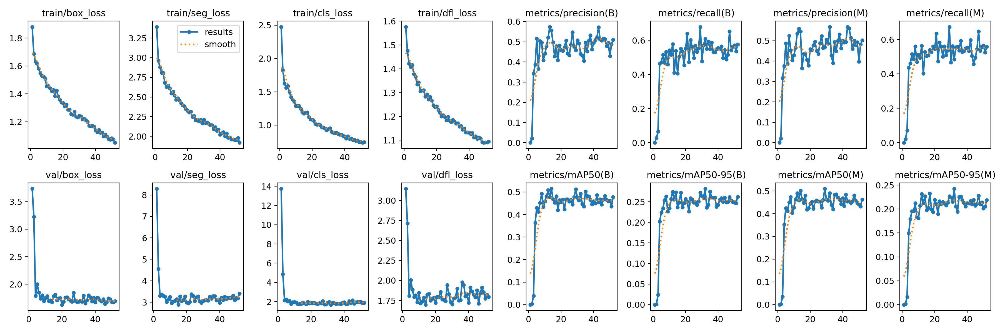

In [ ]:
results_path = f"{saved_model_results_path}/train/results.png"
Image(results_path, width=1000)

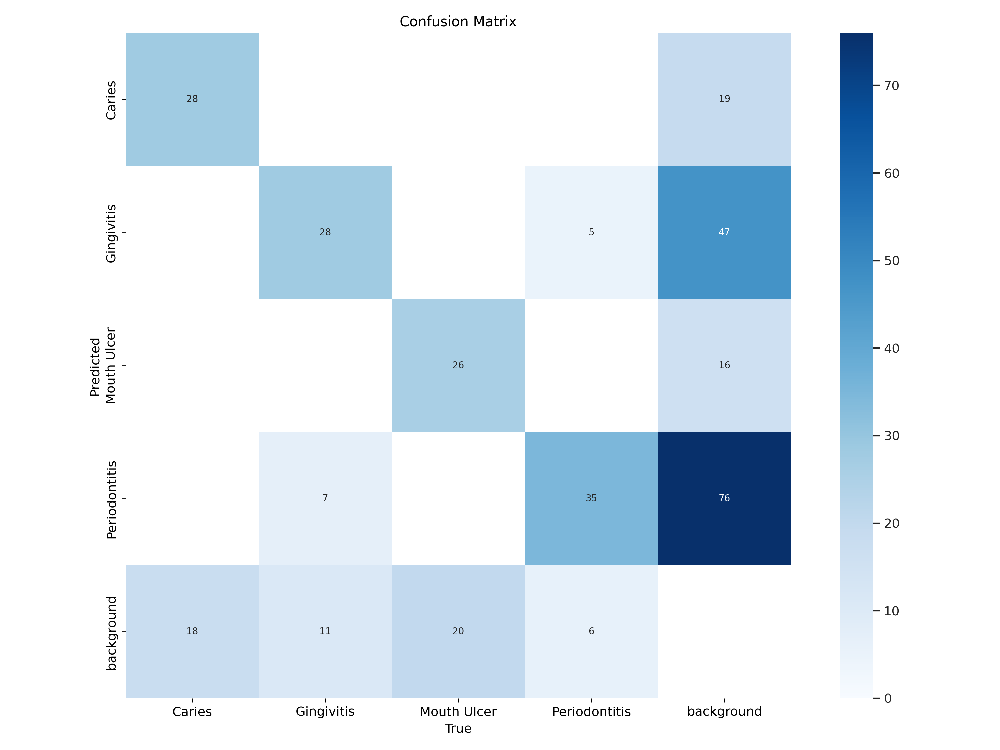

In [ ]:
confusion_matrix_path = f"{saved_model_results_path}/train/confusion_matrix.png"
Image(confusion_matrix_path, width=800)

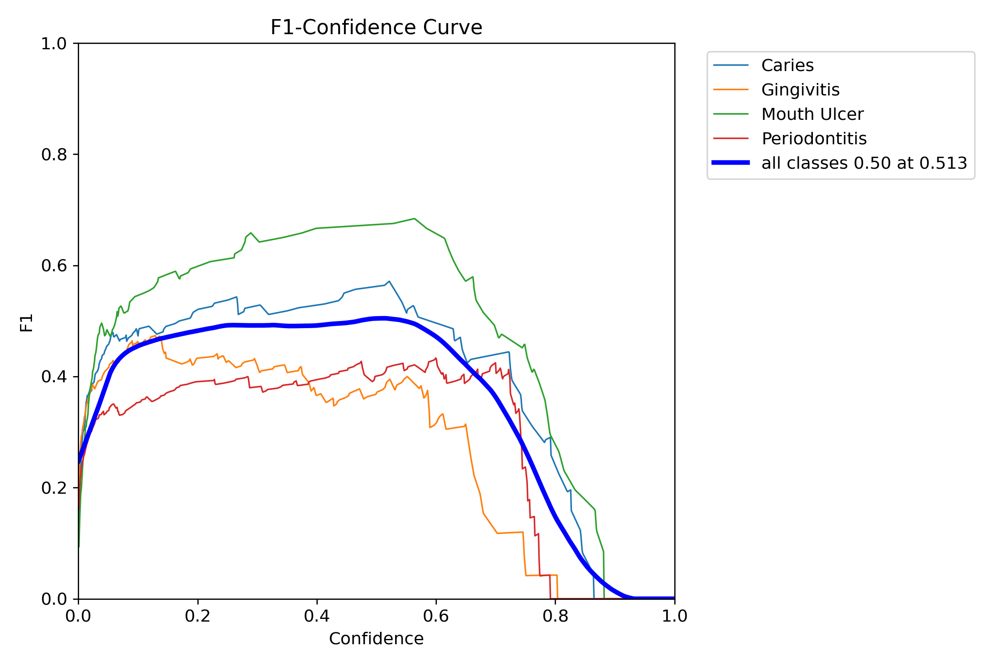

In [ ]:
# mask or segmentation f1 score
f1_curve_path = f"{saved_model_results_path}/train/MaskF1_curve.png"
Image(f1_curve_path, width=800)

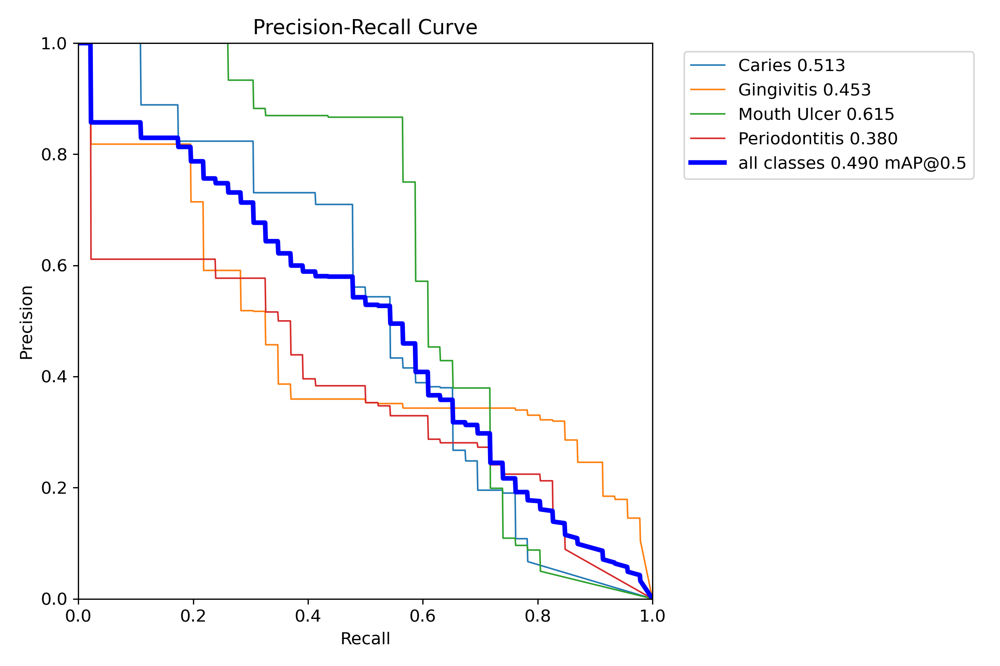

In [ ]:
pr_curve = f"{saved_model_results_path}/train/MaskPR_curve.png"
Image(pr_curve, width=800)

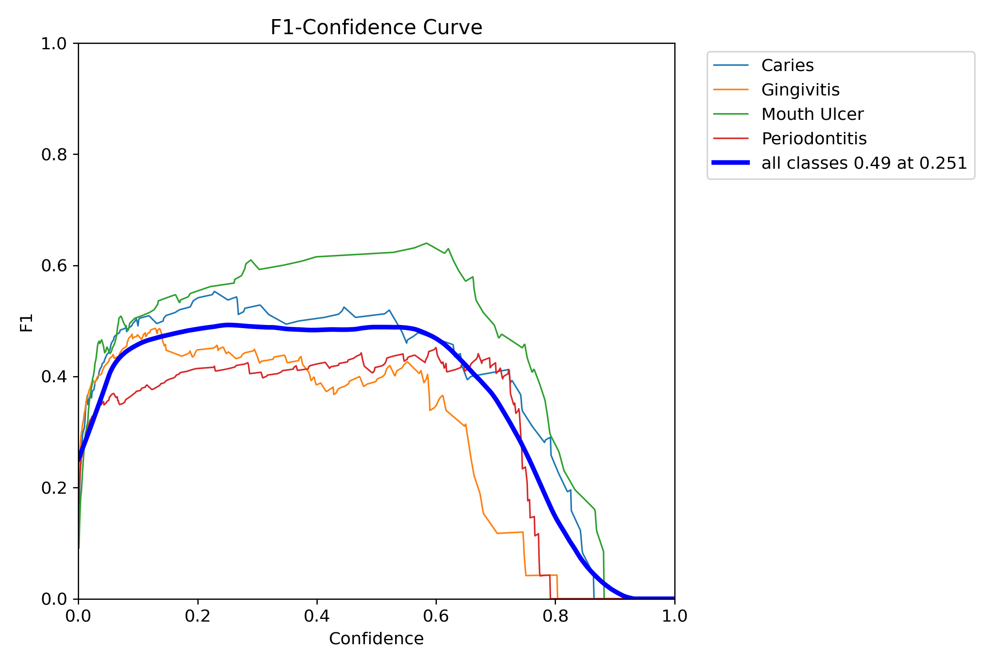

In [ ]:
# bounding box or detection f1 score
f1_curve_box_path = f"{saved_model_results_path}/train/BoxF1_curve.png"
Image(f1_curve_box_path, width=800)

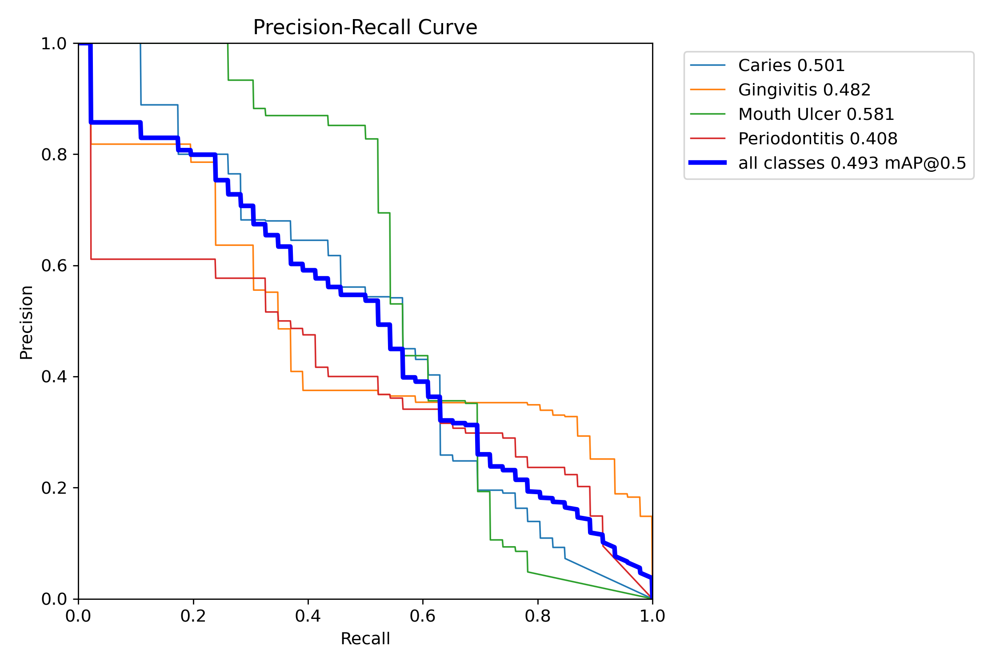

In [ ]:
pr_curve_box_path = f"{saved_model_results_path}/train/BoxPR_curve.png"
Image(pr_curve_box_path, width=800)

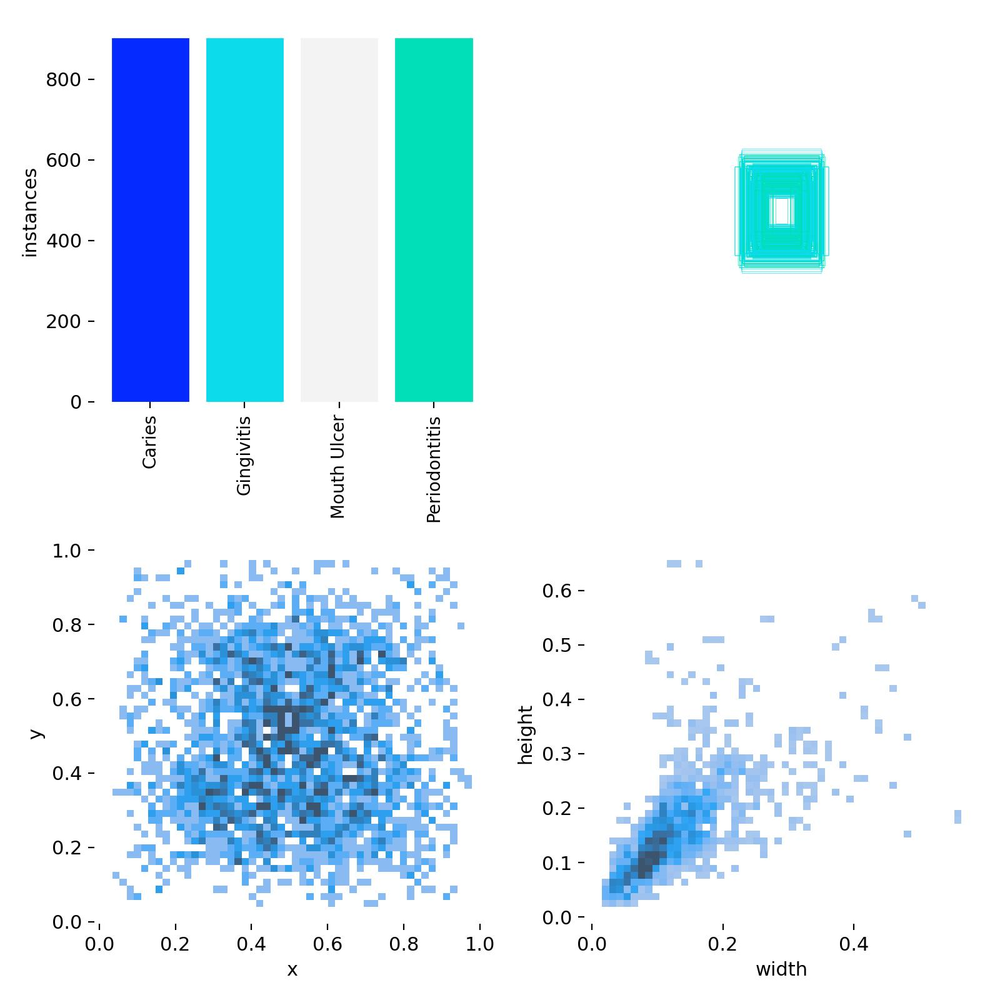

In [ ]:
labels_path = f"{saved_model_results_path}/train/labels.jpg"
Image(labels_path, width=600)

In [ ]:
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
ft_loaded_best_model = YOLO(best_weights_path)

In [ ]:
ft_loaded_best_model.val()

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s-seg summary (fused): 113 layers, 10,068,364 parameters, 0 gradients, 35.3 GFLOPs


val: Scanning /content/datasets/dental_disease_seg_baln_reaug-3/valid/labels.cache... 77 images, 0 backgrounds, 0 corrupt: 100%|██████████| 77/77 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):   0%|          | 0/5 [00:00<?, ?it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  20%|██        | 1/5 [00:00<00:02,  1.56it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  40%|████      | 2/5 [00:01<00:02,  1.16it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:05<00:00,  1.00s/it]


                   all         77        184      0.446      0.614        0.5      0.282      0.567      0.484       0.49      0.242
                Caries         22         46      0.554      0.565      0.531      0.214      0.687      0.478      0.513      0.204
            Gingivitis         12         46      0.348      0.609       0.48      0.294      0.418      0.348      0.451      0.212
           Mouth Ulcer         29         46      0.593      0.543      0.581      0.399      0.836      0.565      0.615      0.378
         Periodontitis         19         46      0.287      0.739      0.409      0.222      0.327      0.543       0.38      0.172
Speed: 7.9ms preprocess, 17.5ms inference, 0.0ms loss, 4.6ms postprocess per image
Results saved to runs/segment/val


ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d7429e5b990>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0

## Validate and Plotting validation results

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs/segment/val"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/fine_tuned/segment/val"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs/segment/val have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/fine_tuned/segment/val.


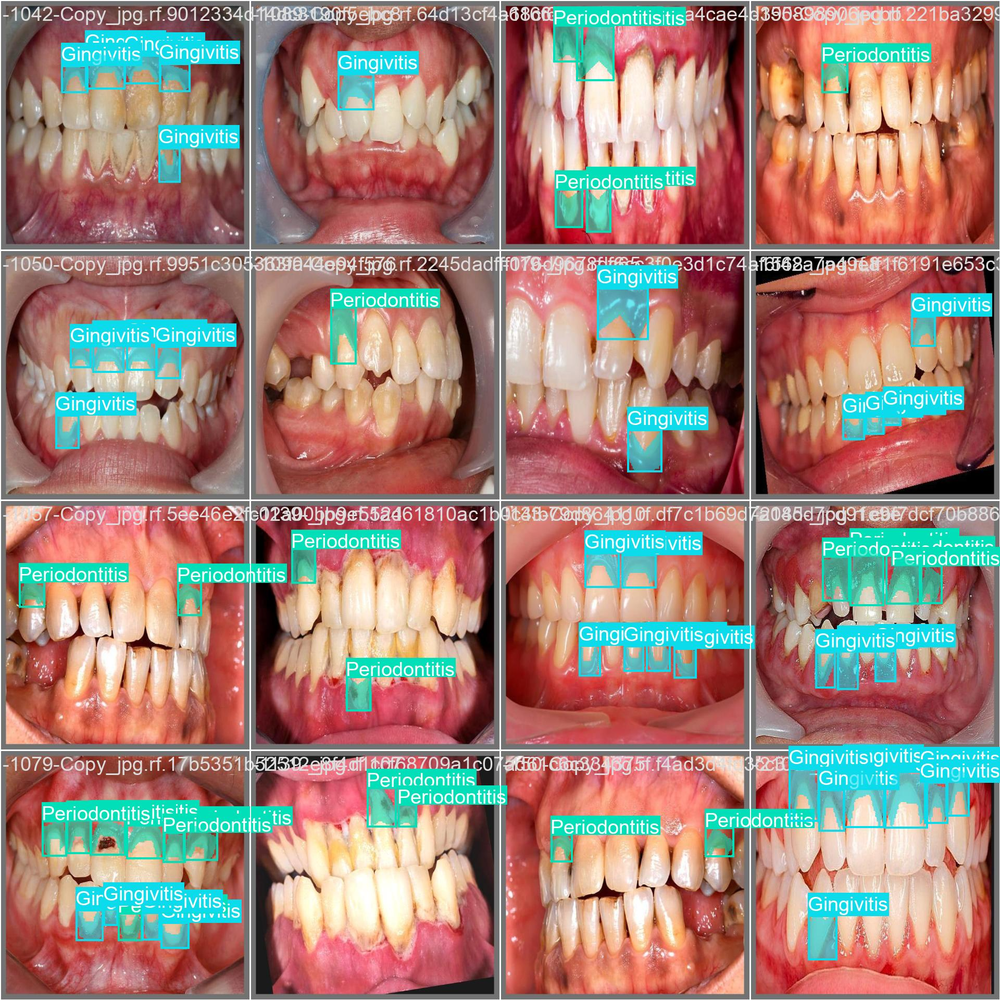

In [ ]:
validation_batch_labels = f"{saved_model_results_path}/val/val_batch0_labels.jpg"
Image(validation_batch_labels, width=1000)

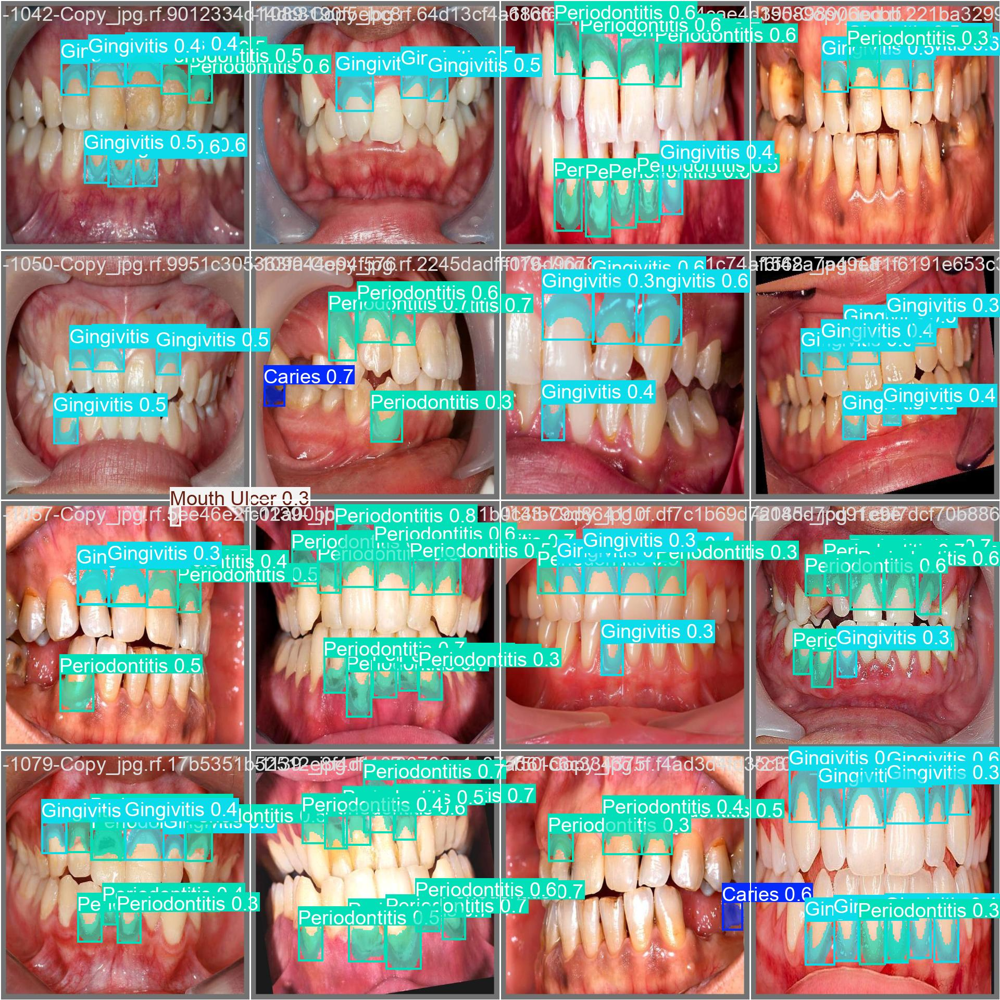

In [ ]:
validation_batch_pred = f"{saved_model_results_path}/val/val_batch0_pred.jpg"
Image(validation_batch_pred, width=1000)

100%|██████████| 16.4k/16.4k [00:00<00:00, 31.2MB/s]


image 1/1 /content/datasets/CAC522B5-A1CC-225C-2AB6559C48211767.jpg: 448x640 2 Gingivitiss, 124.3ms
Speed: 3.0ms preprocess, 124.3ms inference, 19.2ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


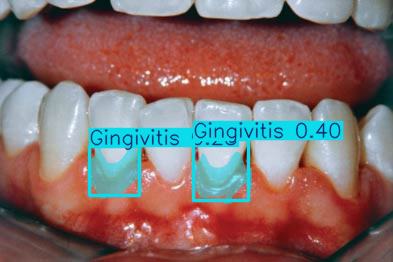

In [ ]:
custom_image_path = "https://cached.imagescaler.hbpl.co.uk/resize/scaleWidth/815/cached.offlinehbpl.hbpl.co.uk/news/PGH/CAC522B5-A1CC-225C-2AB6559C48211767.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 20.1k/20.1k [00:00<00:00, 29.0MB/s]

image 1/1 /content/datasets/dental-caries-web.jpeg: 448x640 1 Caries, 17.0ms
Speed: 6.0ms preprocess, 17.0ms inference, 2.8ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


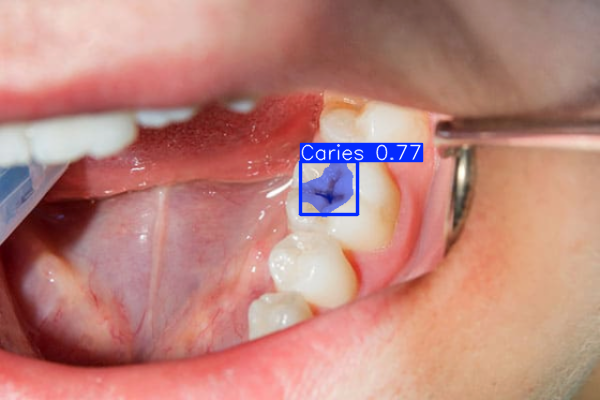

In [ ]:
custom_image_path = "https://www.plagedentistry.com/wp-content/uploads/2020/10/dental-caries-web.jpeg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 25.6k/25.6k [00:00<00:00, 1.31MB/s]

image 1/1 /content/datasets/caries-dental-en-diente-400x400.jpg: 640x640 1 Caries, 24.3ms
Speed: 4.4ms preprocess, 24.3ms inference, 5.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to runs/segment/predict


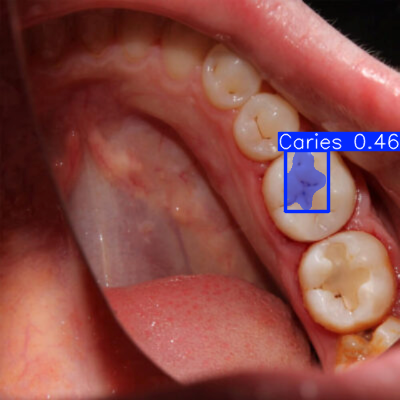

In [ ]:
custom_image_path = "https://famident.hn/wp-content/uploads/2024/10/caries-dental-en-diente-400x400.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

In [ ]:
custom_image_path = "https://www.smysecret.com/blog/wp-content/uploads/2022/09/que-son-las-caries.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

Output hidden; open in https://colab.research.google.com to view.

100%|██████████| 68.6k/68.6k [00:00<00:00, 6.63MB/s]

image 1/1 /content/datasets/figure-2-2.jpg: 448x640 2 Cariess, 16.8ms
Speed: 3.3ms preprocess, 16.8ms inference, 2.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


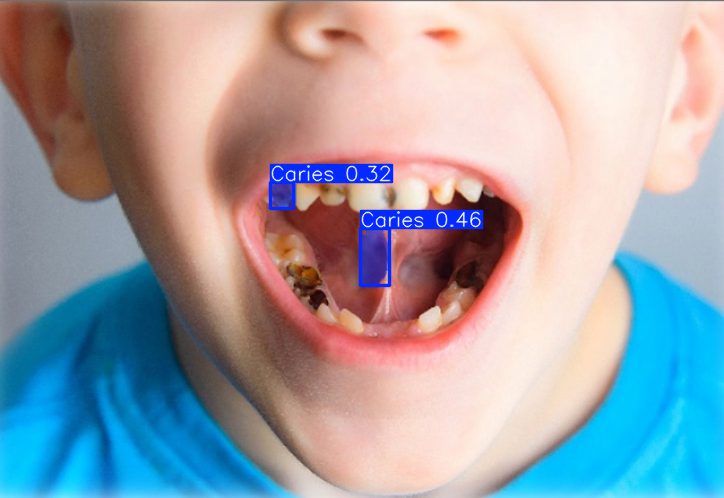

In [ ]:
custom_image_path = "https://dmhuk8np1ucwy.cloudfront.net/up/2023/09/figure-2-2.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 49.3k/49.3k [00:00<00:00, 8.99MB/s]

image 1/1 /content/datasets/Gingivitis-body2-1024x575.jpg: 384x640 5 Gingivitiss, 95.0ms
Speed: 3.2ms preprocess, 95.0ms inference, 2.7ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/segment/predict


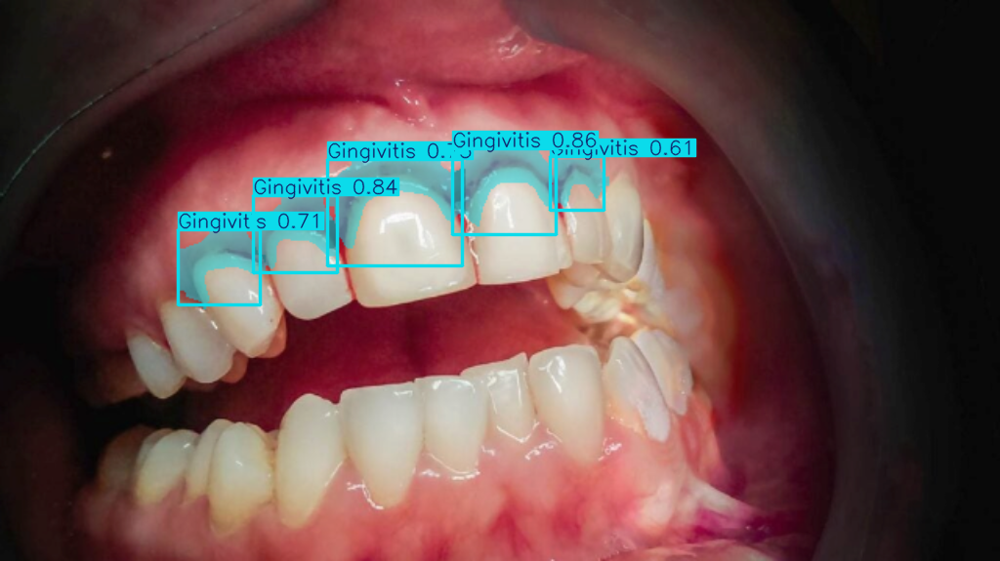

In [ ]:
custom_image_path = "https://post.medicalnewstoday.com/wp-content/uploads/sites/3/2022/01/Gingivitis-body2-1024x575.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 103k/103k [00:00<00:00, 1.45MB/s]

image 1/1 /content/datasets/What-Causes-Mouth-Ulcers-And-How-Can-I-Prevent-Them_-1200x900.jpg: 480x640 1 Mouth Ulcer, 62.5ms
Speed: 2.8ms preprocess, 62.5ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 640)
Results saved to runs/segment/predict


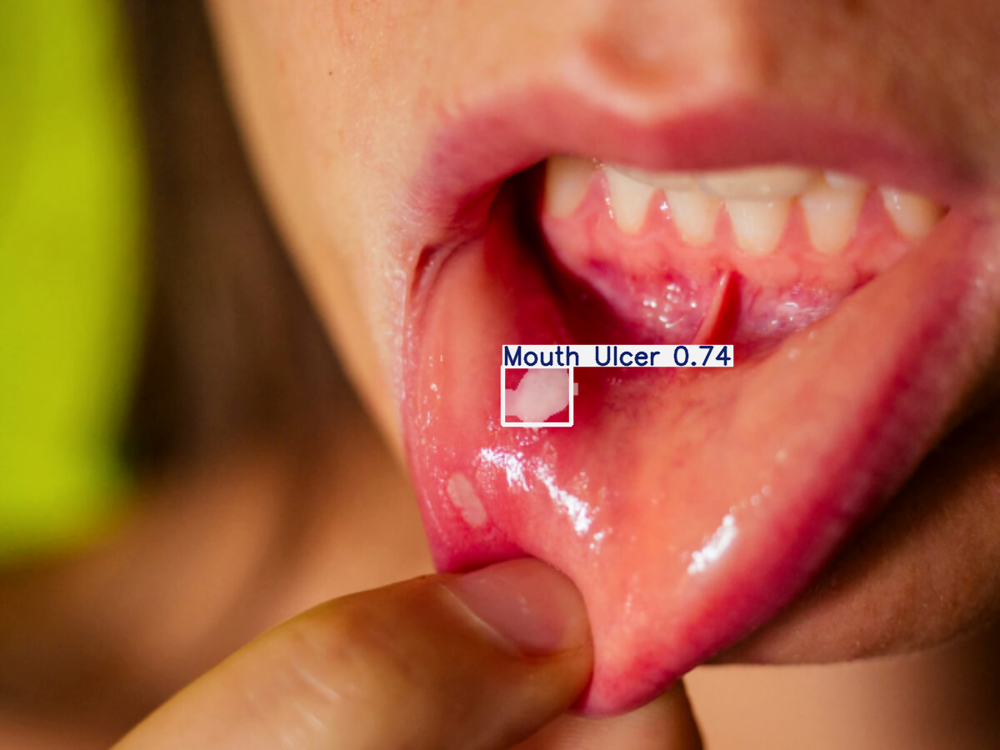

In [ ]:
custom_image_path = "https://www.sintondental.com/wp-content/uploads/2024/01/What-Causes-Mouth-Ulcers-And-How-Can-I-Prevent-Them_-1200x900.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 48.2k/48.2k [00:00<00:00, 1.67MB/s]

image 1/1 /content/datasets/Gingivitis-vs-Periodontitis.webp: 448x640 4 Gingivitiss, 1 Periodontitis, 16.2ms
Speed: 2.3ms preprocess, 16.2ms inference, 2.2ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


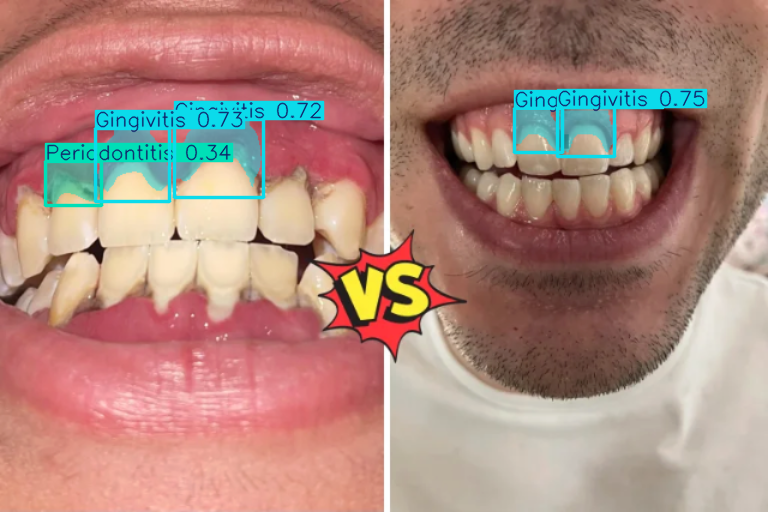

In [ ]:
custom_image_path = "https://www.orisdentalcenter.ae/blog/wp-content/uploads/2024/11/Gingivitis-vs-Periodontitis.webp"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 258k/258k [00:00<00:00, 10.5MB/s]

image 1/1 /content/datasets/8318-Digest-Basics-PerioFig1.jpg: 384x640 2 Gingivitiss, 10 Periodontitiss, 14.4ms
Speed: 2.0ms preprocess, 14.4ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/segment/predict


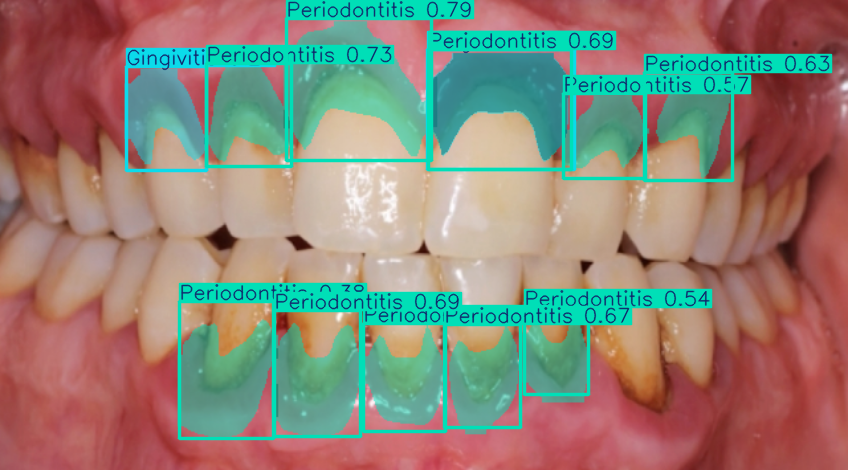

In [ ]:
custom_image_path = "https://assets.speareducation.com/digest/2024/02/back-to-basics-1-diagnosing-periodontitis-2018-classification/8318-Digest-Basics-PerioFig1.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

# Scaling up fine tuning all layers

## Download data

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

!mkdir {HOME}/datasets
%cd {HOME}/datasets

from roboflow import Roboflow
from google.colab import userdata

roboflow_api_key = userdata.get('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("pranta").project("oralcure_dataset")
version = project.version(4)
dataset = version.download("yolov11")

/content
/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dental_disease_seg_baln_reaug-4 in yolov11:: 100%|██████████| 8040/8040 [00:01<00:00, 5240.50it/s]


## Get fine tuned model

In [ ]:
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/fine_tuned"
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
# load the last checkpoint of partial fine tuned model
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
last_weights_path = f"{saved_model_results_path}/train/weights/last.pt"

fine_tuned_last_model = YOLO(last_weights_path)
fine_tuned_last_model.resume = True

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
scaled_up_results = fine_tuned_last_model.train(
    data=f"{dataset.location}/data.yaml",
    pretrained=best_weights_path,
    epochs=200,
    imgsz=640,
    batch=32,
    freeze=None,
    lr0=0.005,
    optimizer='AdamW',
    warmup_epochs=0,
    cos_lr=True,
    patience=20,
    amp=True,
    save=True,
    plots=True,
    device=0,
    seed=42
)

Ultralytics 8.3.121 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/fine_tuned/segment/train/weights/last.pt, data=/content/datasets/dental_disease_seg_baln_reaug-4/data.yaml, epochs=200, time=None, patience=20, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train, exist_ok=False, pretrained=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/fine_tuned/segment/train/weights/best.pt, optimizer=AdamW, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnosti

100%|██████████| 755k/755k [00:00<00:00, 37.4MB/s]


                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  3                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  4                  -1  1    103360  ultralytics.nn.modules.block.C3k2            [128, 256, 1, False, 0.25]    
  5                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  6                  -1  1    346112  ultralytics.nn.modules.block.C3k2            [256, 256, 1, True]           
  7                  -1  1   1180672  ultralytics.nn.modules.conv.Conv             [256

 23        [16, 19, 22]  1   1475452  ultralytics.nn.modules.head.Segment          [4, 32, 128, [128, 256, 512]] 
YOLO11s-seg summary: 203 layers, 10,083,836 parameters, 10,083,820 gradients, 35.6 GFLOPs

Transferred 561/561 items from pretrained weights
Freezing layer 'model.23.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...


100%|██████████| 5.35M/5.35M [00:00<00:00, 165MB/s]


AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1152.6±693.6 MB/s, size: 63.9 KB)


... (136 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  50%|█████     | 1/2 [00:01<00:01,  1.09s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:01<00:00,  1.18it/s]


                   all         77        184      0.491      0.543      0.488      0.258       0.55      0.489      0.481      0.221
                Caries         22         46       0.55      0.425      0.472      0.193      0.641       0.37      0.479      0.186
            Gingivitis         12         46      0.433       0.63       0.46      0.272      0.444      0.543       0.44      0.203
           Mouth Ulcer         29         46      0.652      0.531      0.587      0.354      0.779      0.543      0.595      0.327
         Periodontitis         19         46      0.329      0.587      0.433      0.212      0.336        0.5       0.41      0.169
Speed: 0.2ms preprocess, 6.1ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to runs/segment/train


In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/scaled_up"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/scaled_up.


In [ ]:
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
from IPython.display import Image

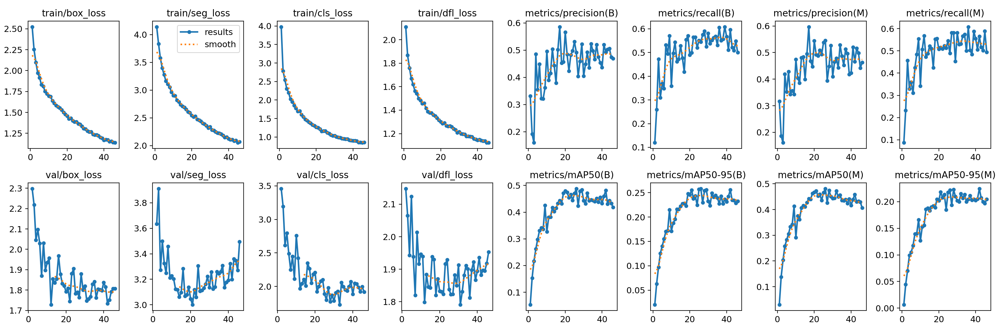

In [ ]:
results_path = f"{saved_model_results_path}/train/results.png"
Image(results_path, width=1000)

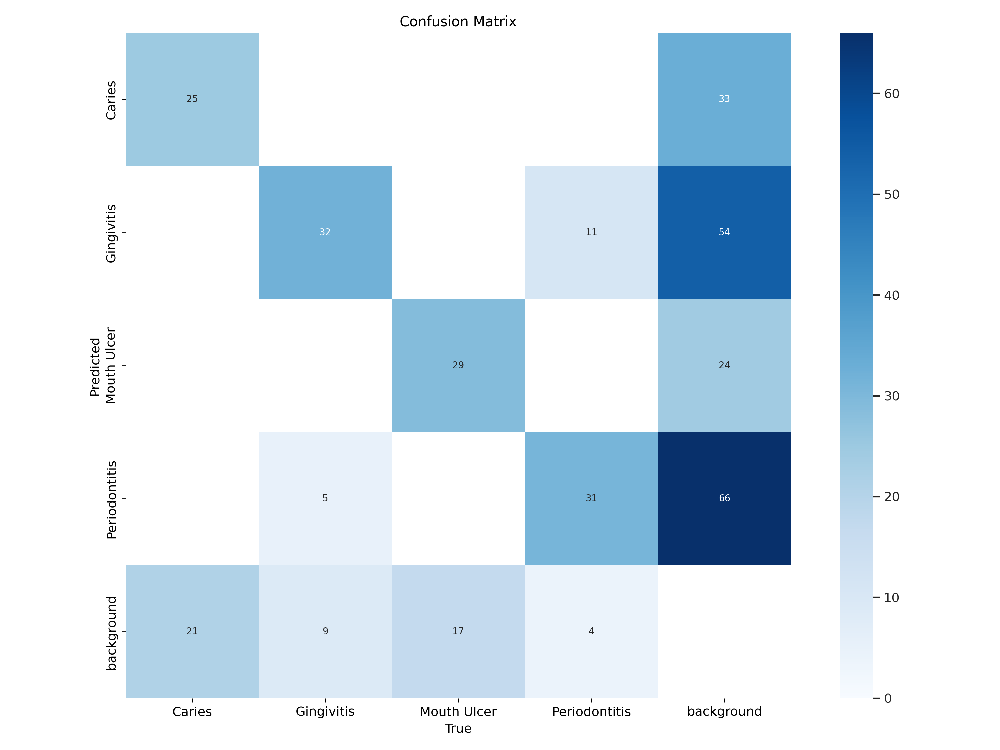

In [ ]:
confusion_matrix_path = f"{saved_model_results_path}/train/confusion_matrix.png"
Image(confusion_matrix_path, width=800)

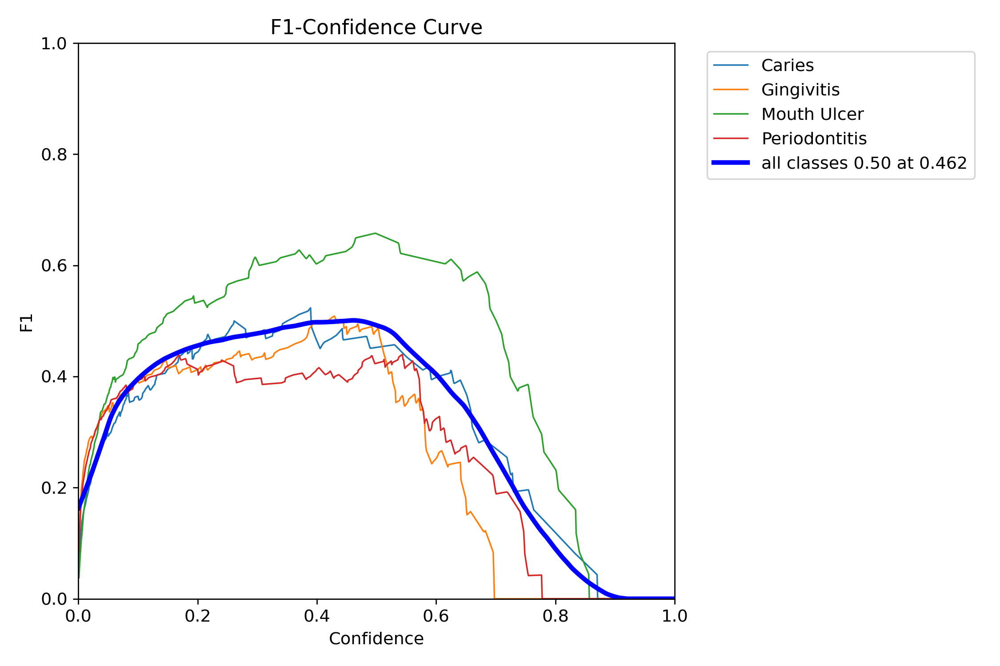

In [ ]:
# mask or segmentation f1 score
f1_curve_path = f"{saved_model_results_path}/train/MaskF1_curve.png"
Image(f1_curve_path, width=800)

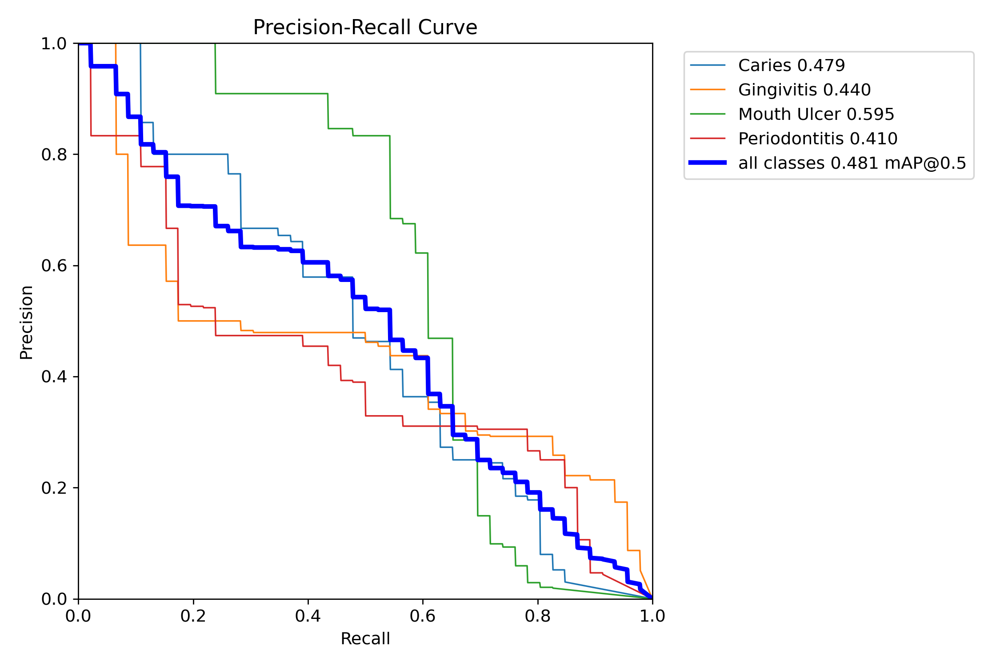

In [ ]:
pr_curve = f"{saved_model_results_path}/train/MaskPR_curve.png"
Image(pr_curve, width=800)

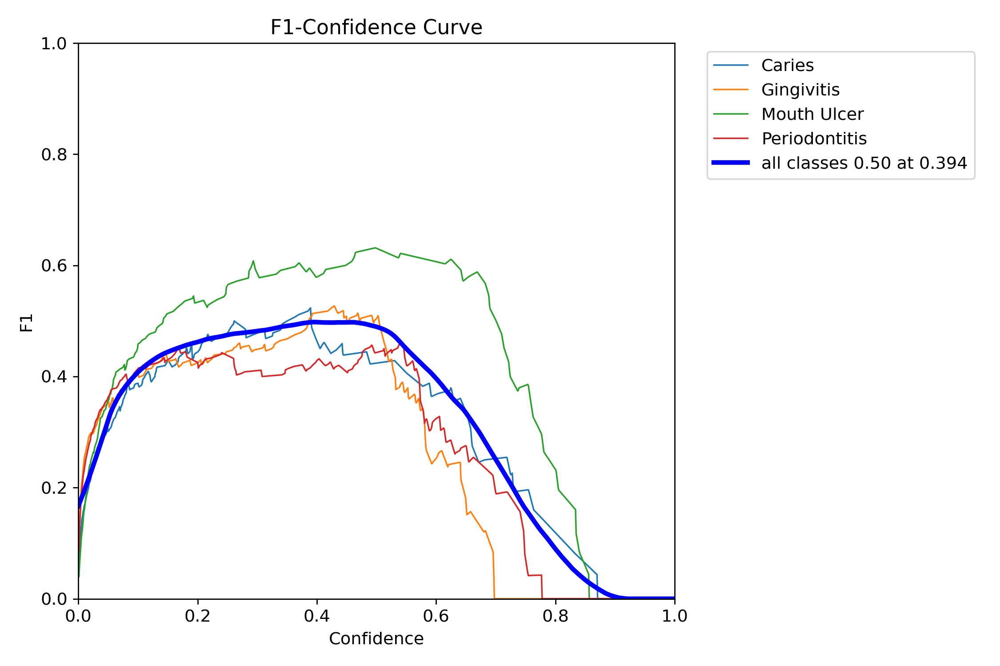

In [ ]:
# bounding box or detection f1 score
f1_curve_box_path = f"{saved_model_results_path}/train/BoxF1_curve.png"
Image(f1_curve_box_path, width=800)

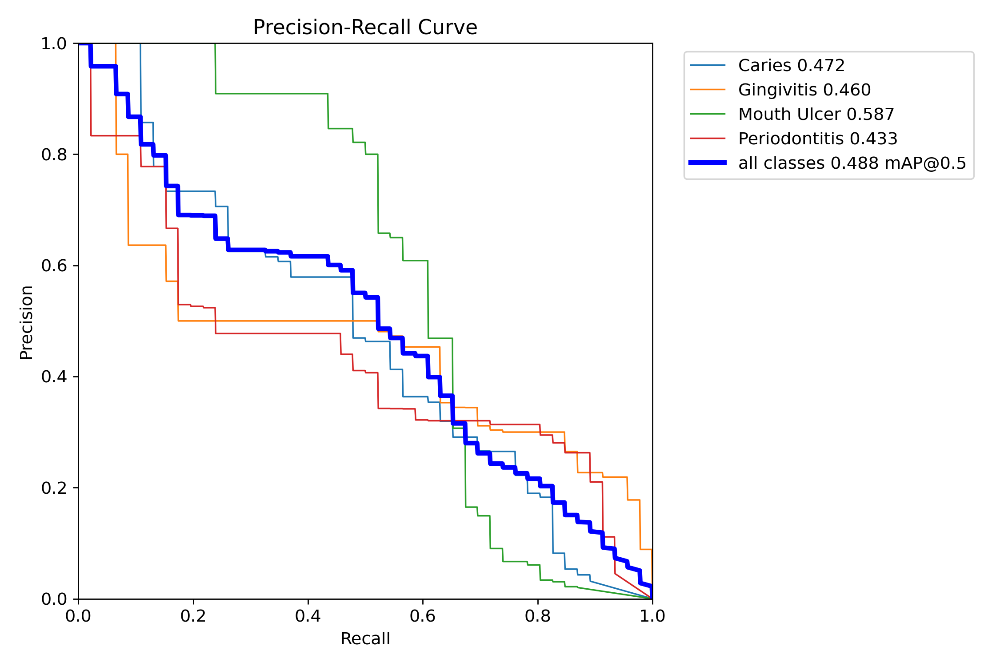

In [ ]:
pr_curve_box_path = f"{saved_model_results_path}/train/BoxPR_curve.png"
Image(pr_curve_box_path, width=800)

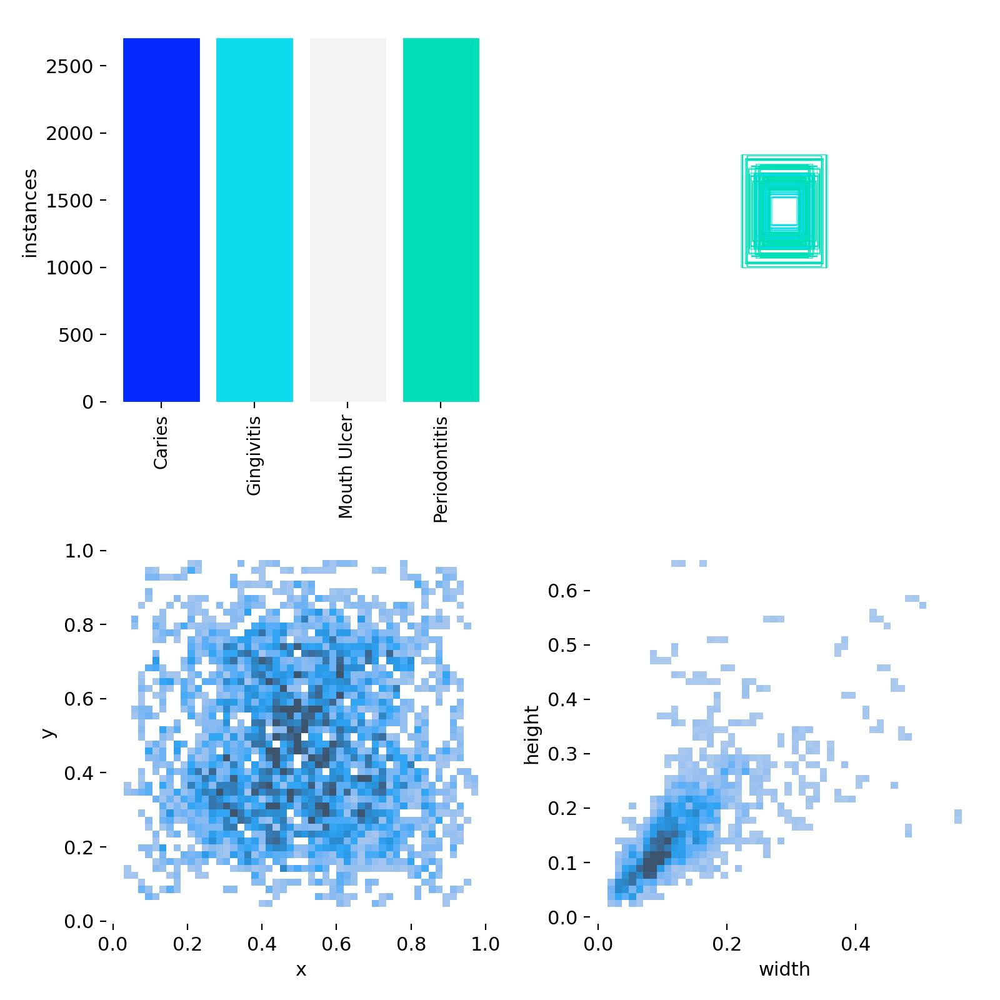

In [ ]:
labels_path = f"{saved_model_results_path}/train/labels.jpg"
Image(labels_path, width=800)

## Validation

In [ ]:
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
scaled_up_loaded_best_model = YOLO(best_weights_path)

In [ ]:
scaled_up_loaded_best_model.val()

Ultralytics 8.3.121 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s-seg summary (fused): 113 layers, 10,068,364 parameters, 0 gradients, 35.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1342.3±358.0 MB/s, size: 37.7 KB)


val: Scanning /content/datasets/dental_disease_seg_baln_reaug-4/valid/labels.cache... 77 images, 0 backgrounds, 0 corrupt: 100%|██████████| 77/77 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):   0%|          | 0/5 [00:00<?, ?it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  20%|██        | 1/5 [00:00<00:02,  1.58it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  40%|████      | 2/5 [00:01<00:03,  1.05s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:06<00:00,  1.20s/it]


                   all         77        184      0.536      0.493      0.488      0.258      0.548      0.492      0.481      0.223
                Caries         22         46      0.624      0.362      0.473      0.194      0.661      0.382       0.48      0.188
            Gingivitis         12         46      0.458      0.565       0.46      0.272      0.442      0.543      0.441      0.202
           Mouth Ulcer         29         46      0.721      0.522      0.586      0.354      0.756      0.543      0.595       0.33
         Periodontitis         19         46      0.341      0.522      0.432      0.211      0.332        0.5      0.409      0.172
Speed: 5.6ms preprocess, 16.7ms inference, 0.0ms loss, 6.7ms postprocess per image
Results saved to runs/segment/val


ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a7ee0d99810>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs/segment/val"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/scaled_up/segment/val"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs/segment/val have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11s-seg/scaled_up/segment/val.


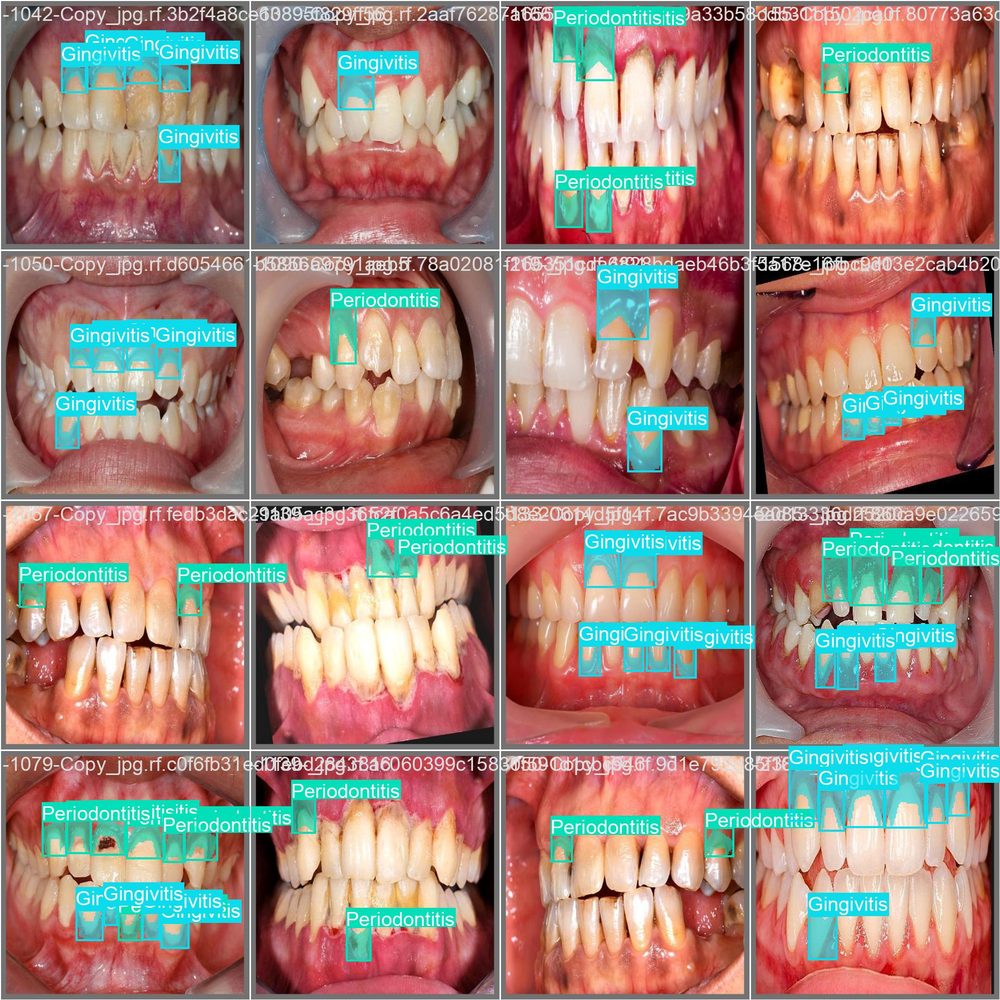

In [ ]:
validation_batch_labels = f"{saved_model_results_path}/val/val_batch0_labels.jpg"
Image(validation_batch_labels, width=1000)

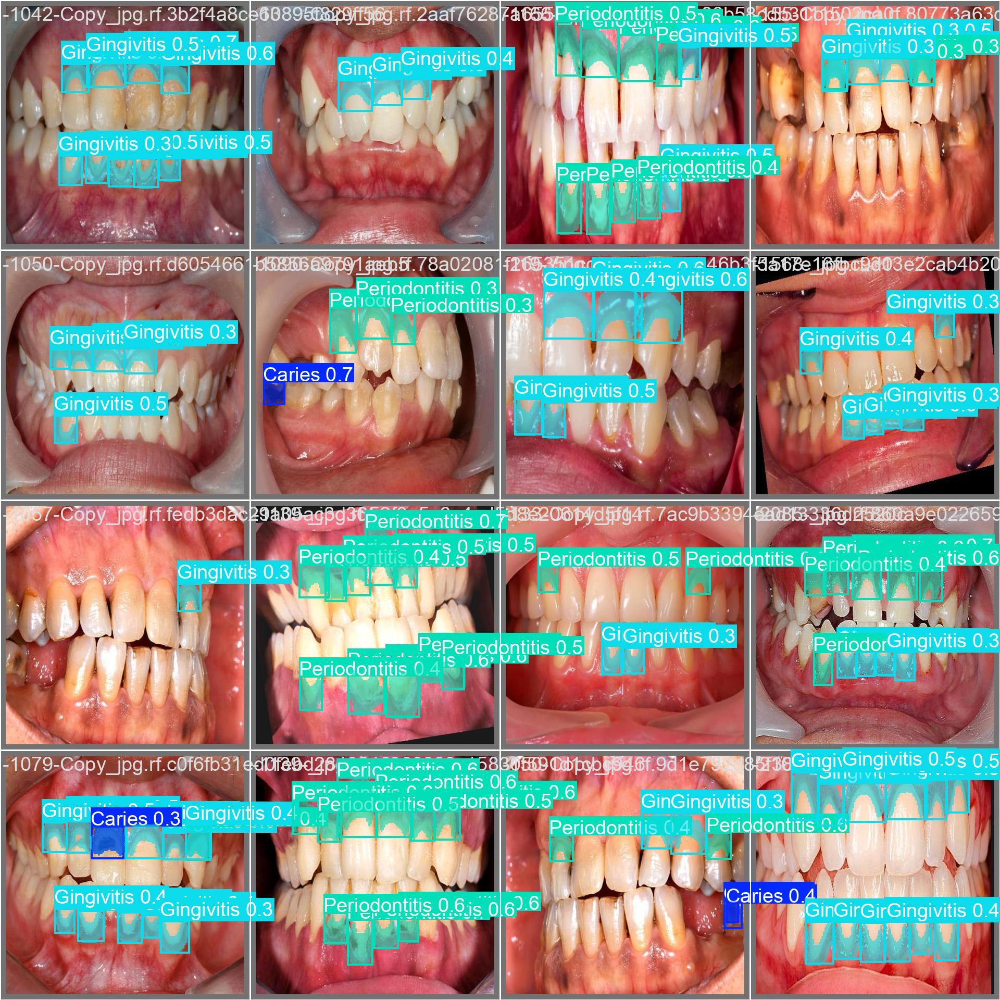

In [ ]:
validation_batch_pred = f"{saved_model_results_path}/val/val_batch0_pred.jpg"
Image(validation_batch_pred, width=1000)

100%|██████████| 48.2k/48.2k [00:00<00:00, 9.29MB/s]

image 1/1 /content/datasets/Gingivitis-vs-Periodontitis.webp: 448x640 4 Gingivitiss, 1 Periodontitis, 64.6ms
Speed: 2.5ms preprocess, 64.6ms inference, 12.8ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


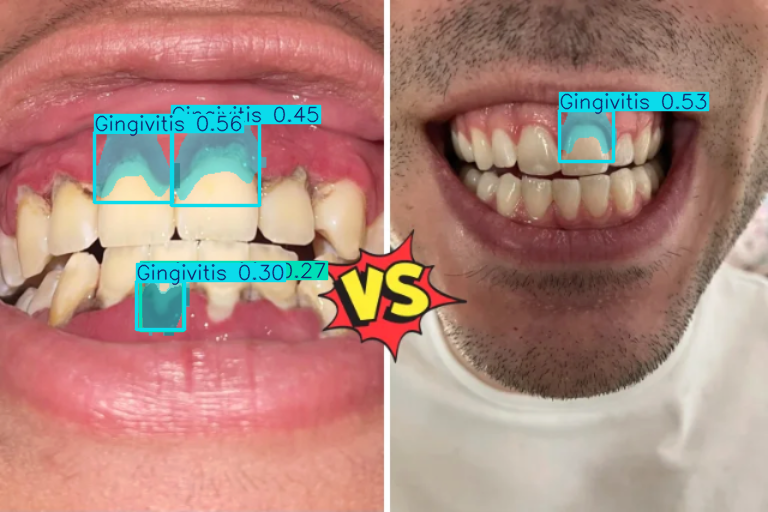

In [ ]:
custom_image_path = "https://www.orisdentalcenter.ae/blog/wp-content/uploads/2024/11/Gingivitis-vs-Periodontitis.webp"
# Perform object detection on an image
results = scaled_up_loaded_best_model(custom_image_path, save=True)
results[0].show()